# Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lr2_helpers as h
from time import perf_counter
from datetime import datetime

from sklearn.linear_model import LinearRegression

import importlib
importlib.reload(h)
curr_time = datetime.now()
print(f"Модули обновлены.\nВремя: {curr_time.strftime('%Y-%m-%d %H:%M:%S')}")

Модули обновлены.
Время: 2026-10-02 12:07:08


In [2]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [10, 8]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

# Лабораторная работа №2

### Загрузка и обработка данных

In [3]:
data = np.loadtxt("ex1data2.txt", delimiter=",")
train_data, test_data = h.train_test(data, test_size=0.3)
X_train, y_train = train_data[:, :(-1)], train_data[:, -1]
X_test, y_test = test_data[:, :(-1)], test_data[:, -1] 
X_train_norm, mean, std = h.featureNormalize(X_train)
X_test_norm, _, _ = h.featureNormalize(X_test, mean, std)

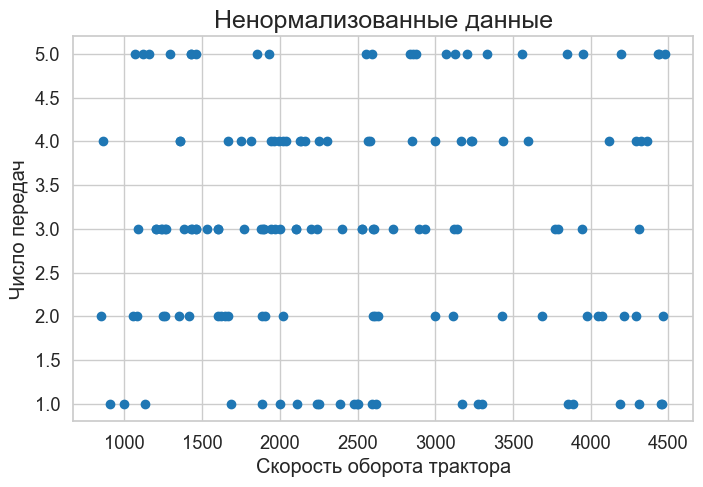

In [4]:
h.plotNorm(X_train[:, 0], X_train[:, 1], title="Ненормализованные данные", figsize=(8, 5))

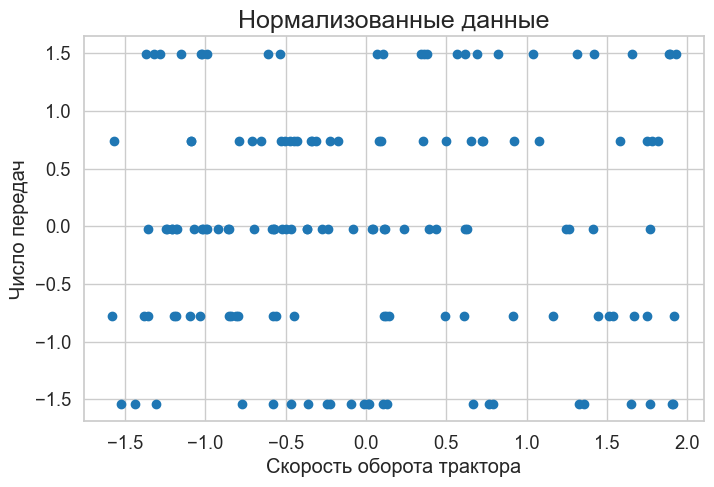

In [5]:
h.plotNorm(X_train_norm[:, 0], X_train_norm[:, 1], title="Нормализованные данные", figsize=(8, 5))

### Проверка работы модели

In [6]:
%%time
model = h.CustomLinearRegression()

model.fit(X_train_norm, y_train, method="analytically")
an_theta = model.theta

model.fit(X_train_norm, y_train, compute_cost=False, method="grad", epochs=50_000)
grad_theta = model.theta

an_theta, grad_theta

CPU times: total: 484 ms
Wall time: 497 ms


(array([406748.9862069 , 132949.37307254, -10107.00145429]),
 array([406748.98620687, 132949.37307252, -10107.00145429]))

### Визуализация

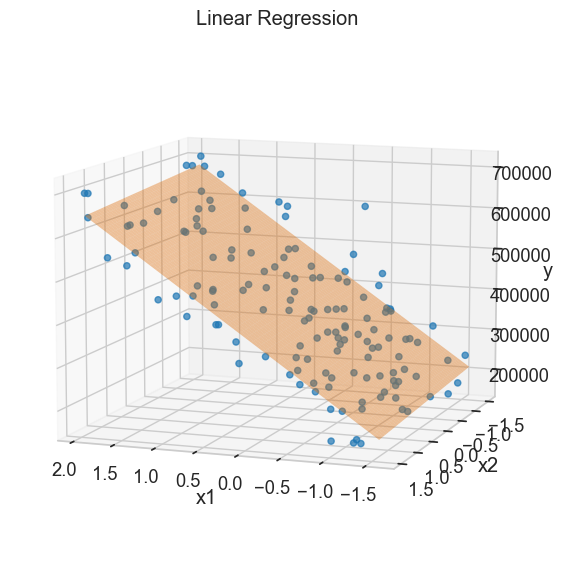

In [7]:
h.plot3d(X_train_norm[:, 0], X_train_norm[:, 1], y_train, grad_theta, figsize=(8, 6))

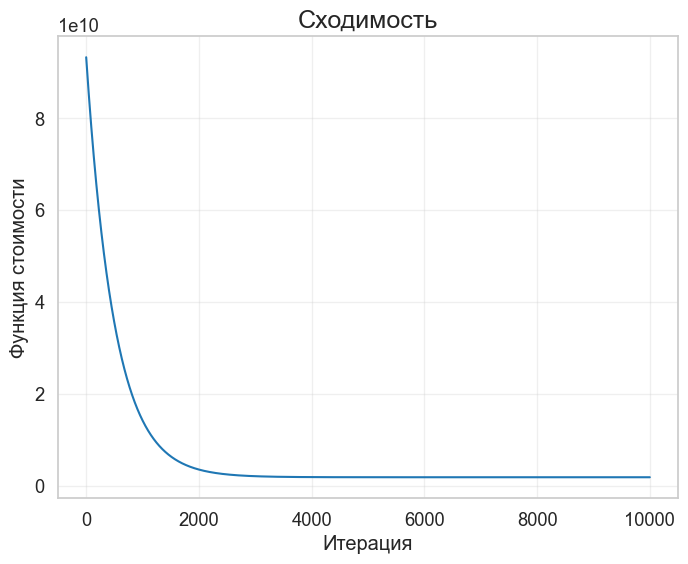

In [8]:
model.fit(X_train_norm, y_train, compute_cost=True, method="grad", epochs=10_000)
iterations, costs = zip(*model.cost)
h.plotCost(iterations, costs, figsize=(8, 6))

### Сбор данных

In [9]:
%%time

rows = []

for method in ["grad", "analytically"]:
    epochs = 1 if method == "analytically" else 50_000
    custom_model = h.CustomLinearRegression()
    
    start_time = perf_counter()
    custom_model.fit(X_train_norm, y_train, compute_cost=False, method=method, epochs=epochs)
    end_time = perf_counter() - start_time
    
    theta = custom_model.theta
    y_pred = custom_model.predict(X_test_norm)
    r2 = h.r2_score(y_test, y_pred)
    row = {"model": f"CustomLinearRegression_{method}", "time": f"{end_time:.4f}", "epochs": epochs, "r2_score": f"{r2:.4f}"}
    rows.append(row)


start_time = perf_counter()
sk_model = LinearRegression()
sk_model.fit(X_train_norm, y_train)
end_time = perf_counter() - start_time
y_pred = sk_model.predict(X_test_norm)
r2 = h.r2_score(y_test, y_pred)

row = {"model": f"SklearnLinearRegression", "time": f"{end_time:.4f}", "epochs": 1, "r2_score": f"{r2:.4f}"}
rows.append(row)

results = pd.DataFrame(rows)
results

CPU times: total: 516 ms
Wall time: 531 ms


,model,time,epochs,r2_score
0,CustomLinearRegression_grad,0.5182,50000,0.8040
1,CustomLinearRegression_analytically,0.0002,1,0.8040
2,SklearnLinearRegression,0.0097,1,0.8040
